In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#**Task 1:**

In [2]:
#Clearing the memory
![ -d tmp ] && ( echo "deleting tmp directory"; rm -rf tmp )
![ -d sample_tile_results ] && !( echo "deleting 'sample_tile_results' directory"; rm -r sample_tile_results)
![ -d sample_wsi_results ] && ( echo "deleting 'sample_wsi_results' directory"; rm -r sample_wsi_results)
![ -d tissue_mask_results ] && ( echo "deleting 'tissue_mask_results' directory"; rm -r tissue_mask_results)
import warnings
warnings.filterwarnings('ignore')

In [3]:
#Installations
!apt-get -y install libopenjp2-7-dev libopenjp2-tools openslide-tools | tail --line 1
!pip install tiatoolbox | tail --line 1
!pip install torch==1.9.1+cu102 torchvision==0.10.1+cu102 -f https://download.pytorch.org/whl/cu102/torch_stable.html --user
ON_GPU = True

0 upgraded, 0 newly installed, 0 to remove and 39 not upgraded.
Looking in links: https://download.pytorch.org/whl/cu102/torch_stable.html


In [4]:
# Following code will download the code files and dataset required for this demo.
import urllib.request
from tqdm import tqdm
from zipfile import ZipFile

code_url = 'https://warwick.ac.uk/study/csde/gsp/eportfolio/directory/pg/saadbashir/code.zip'
data_url = 'https://warwick.ac.uk/study/csde/gsp/eportfolio/directory/pg/saadbashir/data.zip'

class DownloadProgressBar(tqdm):
    def update_to(self, b=1, bsize=1, tsize=None):
        if tsize is not None:
            self.total = tsize
        self.update(b * bsize - self.n)
       
with DownloadProgressBar(unit='B', unit_scale=True, miniters=1, desc='code.zip') as t:
  urllib.request.urlretrieve(code_url, filename='code.zip', reporthook=t.update_to)
with DownloadProgressBar(unit='B', unit_scale=True, miniters=1, desc='data.zip') as t:
  urllib.request.urlretrieve(data_url, filename='data.zip', reporthook=t.update_to)

# Create a ZipFile Object and load models.zip in it
with ZipFile('data.zip', 'r') as zipObj:
  #  Extract all the contents of zip file in current directory
   zipObj.extractall()
# Create a ZipFile Object ando load images.zip in it
with ZipFile('code.zip', 'r') as zipObj:
   # Extract all the contents of zip file in current directory
   zipObj.extractall() 

print('Required code files and data has been downloaded successfully.')

code.zip: 16.4kB [00:00, 29.8kB/s]                            
data.zip: 70.7MB [00:07, 9.85MB/s]                            


Required code files and data has been downloaded successfully.


In [5]:
dataname="orca"

#Set some parameter values
patch_size=500 #size of the tiles to extract and save in the database, must be >= to training size
stride_size=250 #distance to skip between patches, 1 indicated pixel wise extraction, patch_size would result in non-overlapping tiles
mirror_pad_size=250 #number of pixels to pad *after* resize to image with by mirroring (edge's of patches tend not to be analyzed well, so padding allows them to appear more centered in the patch)
test_set_size=0.1 #what percentage of the dataset should be used as a held out validation/testing set
resize=1 #resize input images
classes=[0,1, 2] #what classes we expect to have in the data, here we have only 2 classes but we could add additional classes and/or specify an index from which we would like to ignore

In [6]:
#Imports
import urllib.request
from tqdm import tqdm
from zipfile import ZipFile

from tiatoolbox.models.engine.semantic_segmentor import IOSegmentorConfig, SemanticSegmentor
from tiatoolbox.utils.misc import imread
from tiatoolbox.wsicore.wsireader import WSIReader

import torch
import tables
import os,sys
import numpy as np
np.set_printoptions(threshold=sys.maxsize)
import glob
import PIL
import cv2
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn import model_selection
from sklearn.model_selection import train_test_split
import sklearn.feature_extraction.image
import random

from tiatoolbox.models.engine.semantic_segmentor import IOSegmentorConfig, SemanticSegmentor

seed = random.randrange(sys.maxsize) #get a random seed so that we can reproducibly do the cross validation setup
random.seed(seed) #set the seed
print(f"random seed (note down for reproducibility): {seed} {sklearn.__version__}")

mpl.rcParams['figure.dpi'] = 300 #for high resolution figure in notebook

|2022-03-30|09:24:29.756| [INFO] NumExpr defaulting to 2 threads.


random seed (note down for reproducibility): 786058565811874898 1.0.2


In [7]:
img_dtype = tables.UInt8Atom()  #dtype in which the images will be saved, this indicates that images will be saved as unsigned int 8 bit, i.e., [0,255]
filenameAtom = tables.StringAtom(itemsize=255) #create an atom to store the filename of the image, just incase we need it later, 

In [8]:
files=glob.glob("drive/My Drive/CS424_CB/Courseworks/Coursework_3/validation_100/*.png") # create a list of the files, in this case we're only interested in files which have masks so we can use supervised learning
files_test = glob.glob("drive/My Drive/CS424_CB/Courseworks/Coursework_3/test_100/*.png")

#create training and validation stages and split the files appropriately between them
phases={}
indices = np.arange(100)
np.random.shuffle(indices)
traini = []
for i in range(90):
  traini.append(indices[i] * 2)
vali = []
for i in range(90, 100):
  vali.append(indices[i] * 2)
phases["train"],phases["val"]=traini, vali

#Also add indices for the test files
phases["test"] = 2 * np.arange(100)

#specify that we'll be saving 2 different image types to the database, an image and its associated masked
imgtypes=["img","mask"]

In [9]:
#Form and store the pytables
storage={} #holder for future pytables

block_shape={} #block shape specifies what we'll be saving into the pytable array, here we assume that masks are 1d and images are 3d
block_shape["img"]= np.array((patch_size,patch_size,3))
block_shape["mask"]= np.array((patch_size,patch_size)) 

filters=tables.Filters(complevel=6, complib='zlib') #we can also specify filters, such as compression, to improve storage speed

done = []
for phase in phases.keys(): #now for each of the phases, we'll loop through the files
    print(phase)
    
    totals=np.zeros((2,len(classes))) # we can to keep counts of all the classes in for in particular training, since we 
    totals[0,:]=classes               # can later use this information to create better weights

    hdf5_file = tables.open_file(f"./{dataname}_{phase}.pytable", mode='w') #open the respective pytable
    storage["filename"] = hdf5_file.create_earray(hdf5_file.root, 'filename', filenameAtom, (0,)) #create the array for storage
    
    for imgtype in imgtypes: #for each of the image types, in this case mask and image, we need to create the associated earray
        storage[imgtype]= hdf5_file.create_earray(hdf5_file.root, imgtype, img_dtype,  
                                                  shape=np.append([0],block_shape[imgtype]), 
                                                  chunkshape=np.append([1],block_shape[imgtype]),
                                                  filters=filters)
    for filei in phases[phase]: #now for each of the files
        if ((phase == "train") or (phase == "val")):
            fname=files[filei]
        else:
            fname=files_test[filei]
        if (fname[(len(fname) - 9):len(fname)] == "_mask.png"):
            fname = fname[:len(fname) - 9] + ".png"

        if fname not in done:
            for imgtype in imgtypes:
                if(imgtype=="img"): #if we're looking at an img, it must be 3 channel, but cv2 won't load it in the correct channel order, so we need to fix that
                    if ((phase == "train") or (phase == "val")):
                        io=cv2.cvtColor(cv2.imread("drive/My Drive/CS424_CB/Courseworks/Coursework_3/validation_100/"+os.path.basename(fname)),cv2.COLOR_BGR2RGB)
                    else:
                        io=cv2.cvtColor(cv2.imread("drive/My Drive/CS424_CB/Courseworks/Coursework_3/test_100/"+os.path.basename(fname)),cv2.COLOR_BGR2RGB)
                    interp_method=PIL.Image.BICUBIC

                    io = cv2.resize(io,(0,0),fx=resize,fy=resize, interpolation=interp_method) #resize it as specified above
                    io = np.pad(io, [(mirror_pad_size, mirror_pad_size), (mirror_pad_size, mirror_pad_size), (0, 0)], mode="reflect")
                    
                else: #if its a mask image, then we only need a single channel (since grayscale 3D images are equal in all channels)
                    fname = fname[:len(fname) - 4] + "_mask.png"
                    if ((phase == "train") or (phase == "val")):
                        io_temp=cv2.cvtColor(cv2.imread("drive/My Drive/CS424_CB/Courseworks/Coursework_3/validation_100/"+os.path.basename(fname)),cv2.COLOR_BGR2GRAY) # make sure you read the image as grayscale e.g., in opencv you can use the specify when reading image
                    else:
                        io_temp=cv2.cvtColor(cv2.imread("drive/My Drive/CS424_CB/Courseworks/Coursework_3/test_100/"+os.path.basename(fname)),cv2.COLOR_BGR2GRAY)
                    io = np.zeros(io_temp.shape)
                    io[io_temp > 75] = 1 # remove any noise and make it background
                    io[io_temp >= 200] = 2

                    interp_method=PIL.Image.NEAREST #want to use nearest! otherwise resizing may cause non-existing classes to be produced via interpolation (e.g., ".25")
                    for i, key in enumerate(classes): 
                        totals[1,i]+=sum(sum(io==key))

                    io = cv2.resize(io,(0,0),fx=resize,fy=resize, interpolation=interp_method) #resize it as specified above
                    io = np.pad(io, [(mirror_pad_size, mirror_pad_size), (mirror_pad_size, mirror_pad_size)], mode="reflect")

                # extract small patches out of these big ROIs/HPFs
                io_arr_out = []
                for i in range(0, io.shape[0], patch_size):
                  for j in range(0, io.shape[1], patch_size):
                    patch = io[i:i+patch_size, j:j+patch_size,...]
                    io_arr_out.append(patch)
                
                io_arr_out = np.array(io_arr_out)
              
                #save the 4D tensor to the table
                if(imgtype=="img"):
                    if (io_arr_out.shape[1:] == (500, 500, 3)):
                        storage[imgtype].append(io_arr_out)
                else:
                    if (io_arr_out.shape[1:] == (500, 500)):
                        storage[imgtype].append(io_arr_out) #only need 1 channel for mask data

                done.append(fname)

            storage["filename"].append([fname for x in range(io_arr_out.shape[0])]) #add the filename to the storage array
        
    #lastely, we should store the number of pixels
    npixels=hdf5_file.create_carray(hdf5_file.root, 'numpixels', tables.Atom.from_dtype(totals.dtype), totals.shape)
    npixels[:]=totals
    hdf5_file.close()

train
val
test


In [10]:
#More imports
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms

from PIL import Image
import sklearn.feature_extraction.image
from unet import UNet #code borrowed from https://github.com/jvanvugt/pytorch-unet
import scipy.ndimage 
import time
import math
from sklearn.metrics import confusion_matrix
from skimage import io, morphology

seed = random.randrange(sys.maxsize) #get a random seed so that we can reproducibly do the cross validation setup
random.seed(seed) # set the seed
print(f"random seed (note down for reproducibility): {seed}")

random seed (note down for reproducibility): 8048850910110176379


In [11]:
gpuid = 0

# --- unet params
# these parameters get fed directly into the UNET class, and more description of them can be discovered there
n_classes = 3    #number of classes in the data mask that we'll aim to predict
in_channels = 3  #input channel of the data, RGB = 3
padding = True   #should levels be padded
depth = 5      # depth of the network -- default of 5 for unet

wf= 2           #wf (int): number of filters in the first layer is 2**wf, was 6
up_mode= 'upconv' #should we simply upsample the mask, or should we try and learn an interpolation 
batch_norm = True #should we use batch normalization between the layers

# --- training params
batch_size = 64
patch_size = 256
num_epochs = 1 #  run it for 100 if you like
edge_weight = 1.1 # edges tend to be the most poorly segmented given how little area they 
                  # occupy in the training set, this paramter boosts their values along the lines of the original UNET paper

phases = ["train","val","test"] # how many phases did we create databases for?
validation_phases= ["val"] # when should we do valiation? note that validation is time consuming, @@@@@@Max: Can add train here as well
                           # so as opposed to doing for both training and validation, we do it only for vlaidation at the end of the epoch

ignore_index = -100

In [12]:
#helper function for pretty printing of current time and remaining time
def asMinutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)
def timeSince(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent+.00001)
    rs = es - s
    return '%s (- %s)' % (asMinutes(s), asMinutes(rs))
    
#specify if we should use a GPU (cuda) or only the CPU
if(torch.cuda.is_available()):
    print(torch.cuda.get_device_properties(gpuid))
    torch.cuda.set_device(gpuid)
    device = torch.device(f'cuda:{gpuid}')
else:
    device = torch.device(f'cpu')
    
print(device)

_CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=15109MB, multi_processor_count=40)
cuda:0


In [13]:
#build the model according to the paramters specified above and copy it to the GPU. finally print out the number of trainable parameters
model = UNet(n_classes=n_classes, 
             in_channels=in_channels, 
             padding=padding,depth=depth,
             wf=wf, up_mode=up_mode, 
             batch_norm=batch_norm).to(device)
print(f"total params: \t{sum([np.prod(p.size()) for p in model.parameters()])}")

total params: 	122471


In [14]:
#this defines our dataset class which will be used by the dataloader
class Dataset(object):
    def __init__(self, fname ,img_transform=None, mask_transform = None, edge_weight= False):
        #nothing special here, just internalizing the constructor parameters
        self.fname=fname
        self.edge_weight = edge_weight
        
        self.img_transform=img_transform
        self.mask_transform = mask_transform
        
        self.tables=tables.open_file(self.fname)
        self.numpixels=self.tables.root.numpixels[:]
        self.nitems=self.tables.root.img.shape[0]
        self.tables.close()
        
        self.img = None
        self.mask = None
        
    def __getitem__(self, index):
        # opening should be done in __init__ but seems to be
        # an issue with multithreading so doing here
        with tables.open_file(self.fname,'r') as db:
            self.img=db.root.img
            self.mask=db.root.mask
       
            #get the requested image and mask from the pytable
            img = self.img[index,:,:,:]
            mask = self.mask[index,:,:]

        # the original Unet paper assignes increased weights to the edges of the annotated objects
        # their method is more sophistocated, but this one is faster, we simply dilate the mask and 
        # highlight all the pixels which were "added"
        if(self.edge_weight):
            weight = scipy.ndimage.morphology.binary_dilation(mask==1, iterations =2) & ~mask
        else: # otherwise the edge weight is all ones and thus has no affect
            weight = np.ones(mask.shape,dtype=mask.dtype)
        
        mask = mask[:,:,None].repeat(3,axis=2) # in order to use the transformations given by torchvision
        weight = weight[:,:,None].repeat(3,axis=2) # inputs need to be 3D, so here we convert from 1d to 3d by repetition
        
        img_new = img
        mask_new =mask
        weight_new = weight
        
        seed = random.randrange(sys.maxsize) #get a random seed so that we can reproducibly do the transofrmations
        if self.img_transform is not None:
            random.seed(seed) # apply this seed to img transforms
            img_new = self.img_transform(img)

        if self.mask_transform is not None:
            random.seed(seed)
            mask_new = self.mask_transform(mask)
            mask_new = np.asarray(mask_new)[:,:,0].squeeze()

            random.seed(seed)
            weight_new = self.mask_transform(weight)
            weight_new = np.asarray(weight_new)[:,:,0].squeeze()


        return img_new,  np.array(mask_new),  np.array(weight_new)
    def __len__(self):
        return self.nitems

In [15]:
#note that since we need the transofrmations to be reproducible for both masks and images
#we do the spatial transformations first, and afterwards do any color augmentations
img_transform = transforms.Compose([
     transforms.ToPILImage(),
     transforms.Resize(patch_size),
    transforms.ToTensor()
    ])

mask_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(patch_size),
    ])

dataset={}
dataLoader={}
print(phases)
for phase in phases: #now for each of the phases, we're creating the dataloader
                     #interestingly, given the batch size, i've not seen any improvements from using a num_workers>0
    print(phase)
    dataset[phase] = Dataset(f"{dataname}_{phase}.pytable", 
                             img_transform=img_transform, 
                             mask_transform = mask_transform,
                             edge_weight=edge_weight)
    dataLoader[phase] = DataLoader(dataset[phase], batch_size=batch_size, 
                                shuffle=True, num_workers=0, pin_memory=True) 
    
    print(f'{phase} Dataset compelted')

['train', 'val', 'test']
train
train Dataset compelted
val
val Dataset compelted
test
test Dataset compelted


torch.Size([3, 256, 256]) (256, 256) (256, 256)


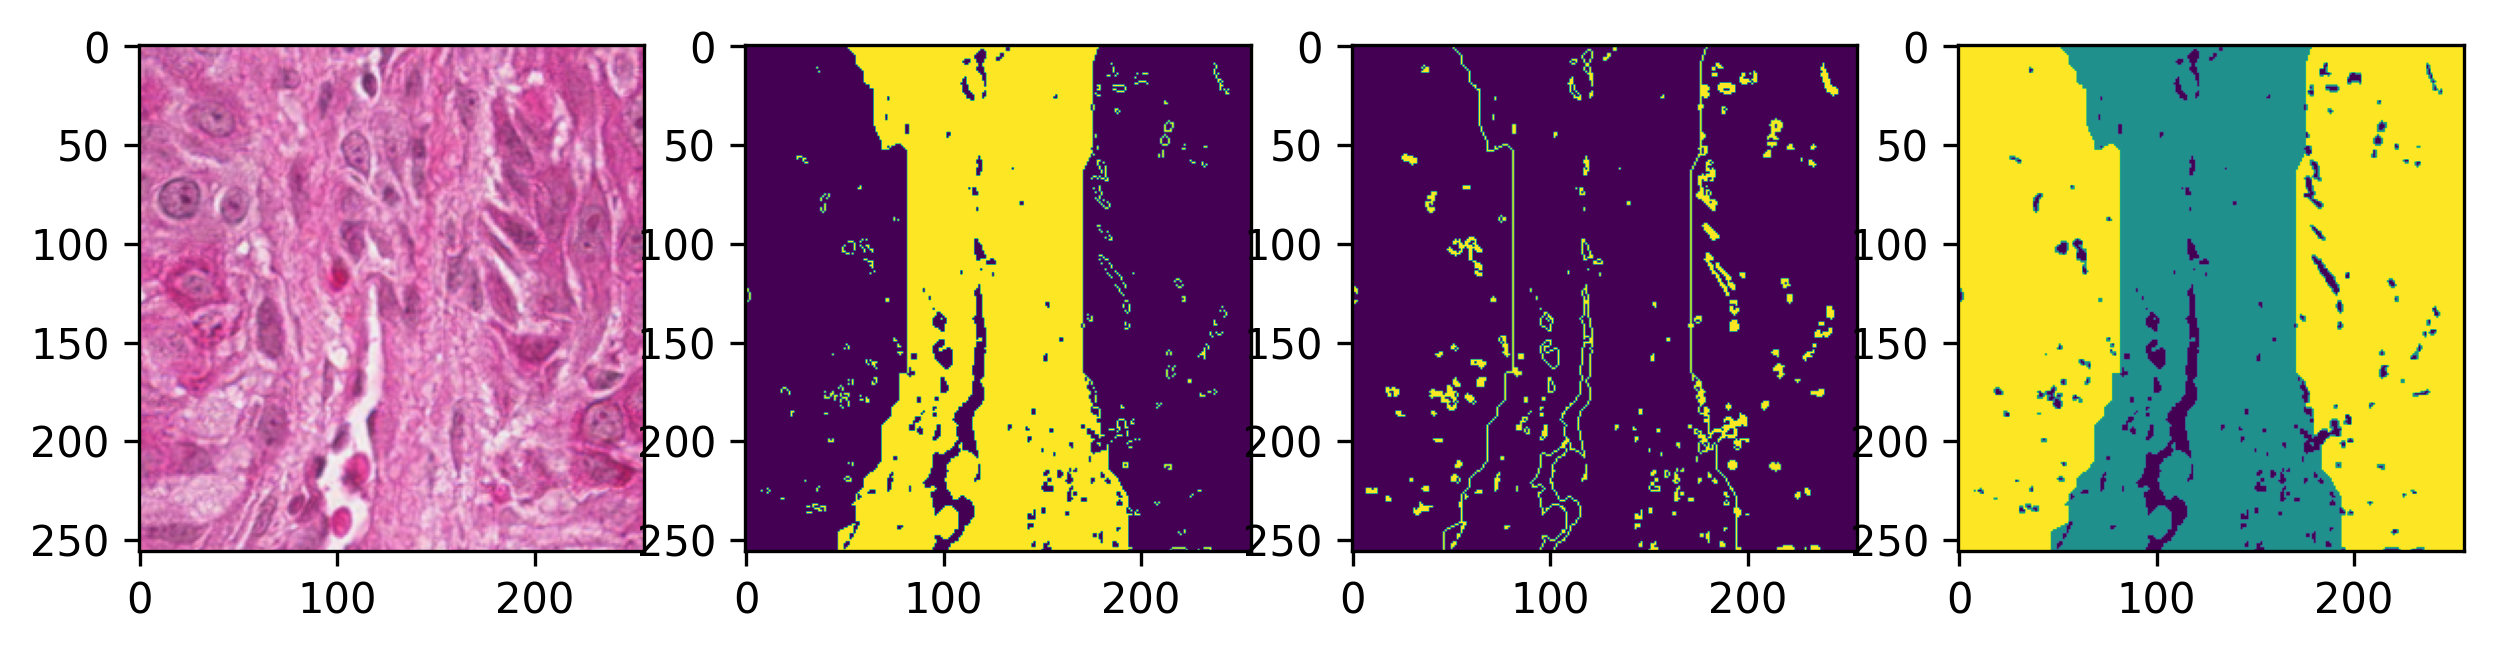

In [16]:
#visualize a single example to verify that it is correct
(img,patch_mask,patch_mask_weight)=dataset["val"][54]

print(img.shape, patch_mask.shape, patch_mask_weight.shape)
fig, ax = plt.subplots(1,4, figsize=(10, 4))  # 1 row, 4 columns

#build output showing original patch  (after augmentation), class = 1 mask, weighting mask, overall mask (to see any ignored classes)
ax[0].imshow(np.moveaxis(img.numpy(),0,-1))
ax[1].imshow(patch_mask==1)
ax[2].imshow(patch_mask_weight)
ax[3].imshow(patch_mask)

In [17]:
optim = torch.optim.Adam(model.parameters()) # Adam is going to be the most robust

In [18]:
#we have the ability to weight individual classes, in this case we'll do so based on their presense in the trainingset
#to avoid biasing any particular class
nclasses = dataset["train"].numpixels.shape[1]
class_weight = dataset["train"].numpixels[1,0:3] #don't take ignored class into account here
class_weight = torch.from_numpy(1-class_weight/class_weight.sum()).type('torch.FloatTensor').to(device)

print(class_weight) # show final used weights, make sure that they're reasonable before continouing
criterion = nn.CrossEntropyLoss(weight = class_weight, ignore_index = ignore_index, reduce=False)
               # reduce = False makes sure we get a 2D output instead of a 1D "summary" value

tensor([0.6930, 0.6765, 0.6306], device='cuda:0')


In [19]:
best_loss_on_test = np.Infinity
edge_weight = torch.tensor(edge_weight).to(device)
start_time = time.time()
for epoch in range(num_epochs):
    print("epoch " + str(epoch))
    #zero out epoch based performance variables 
    all_acc = {key: 0 for key in phases} 
    all_loss = {key: torch.zeros(0).to(device) for key in phases}
    cmatrix = {key: np.zeros((3,3)) for key in phases}

    for phase in phases: #iterate through both training and validation states
        if ((phase == 'train') or (phase == 'val')):
            if phase == 'train':
                model.train()  # Set model to training mode
            else: #when in eval mode, we don't want parameters to be updated
                model.eval()   # Set model to evaluate mode
            
            for ii , (X, y, y_weight) in enumerate(dataLoader[phase]): #for each of the batches
                X = X.to(device)  # [Nbatch, 3, H, W]
                y_weight = y_weight.type('torch.FloatTensor').to(device)
                y = y.type('torch.LongTensor').to(device)  # [Nbatch, H, W] with class indices (0, 1)

                with torch.set_grad_enabled(phase == 'train'): 
                              # dynamically set gradient computation, in case of validation, this isn't needed
                              # disabling is good practice and improves inference time

                    prediction = model(X)  # [N, Nclass, H, W]
                    loss_matrix = criterion(prediction, y)
                    loss = (loss_matrix * (edge_weight**y_weight)).mean() #can skip if edge weight==1

                    if phase=="train": #in case we're in train mode, need to do back propogation
                        optim.zero_grad()
                        loss.backward()
                        optim.step()
                        train_loss = loss

                    all_loss[phase]=torch.cat((all_loss[phase],loss.detach().view(1,-1)))

                    if phase in validation_phases: #if this phase is part of validation, compute confusion matrix
                        p=prediction[:,:,:,:].detach().cpu().numpy()
                        cpredflat=np.argmax(p,axis=1).flatten()
                        yflat=y.cpu().numpy().flatten()

                        cmatrix[phase]=cmatrix[phase]+confusion_matrix(yflat,cpredflat,labels=range(n_classes))

            all_acc[phase]=(cmatrix[phase]/cmatrix[phase].sum()).trace()
            all_loss[phase] = all_loss[phase].cpu().numpy().mean()

    print('%s ([%d/%d] %d%%), train loss: %.4f test loss: %.4f' \
              % (timeSince(start_time, (epoch+1) / num_epochs), 
              epoch+1, num_epochs ,(epoch+1) / num_epochs * 100, all_loss["train"], all_loss["val"]),end="")    

    #if current loss is the best we've seen, save model state with all variables
    #necessary for recreation
    if all_loss["val"] < best_loss_on_test:
        best_loss_on_test = all_loss["val"]
        print("  **")
        state = {'epoch': epoch + 1,
         'model_dict': model.state_dict(),
         'optim_dict': optim.state_dict(),
         'best_loss_on_test': all_loss,
         'n_classes': n_classes,
         'in_channels': in_channels,
         'padding': padding,
         'depth': depth,
         'wf': wf,
         'up_mode': up_mode, 'batch_norm': batch_norm}

        torch.save(state, f"{dataname}_unet_best_model.pth") # saves to current working directory
    else:
      print("")

epoch 0
3m 24s (- -1m 59s) ([1/1] 100%), train loss: 0.4812 test loss: 0.3878  **


In [20]:
checkpoint = torch.load(f"{dataname}_unet_best_model.pth") # load best model from current working directory
model.load_state_dict(checkpoint["model_dict"])

<All keys matched successfully>

torch.Size([3, 256, 256]) (256, 256) (256, 256)


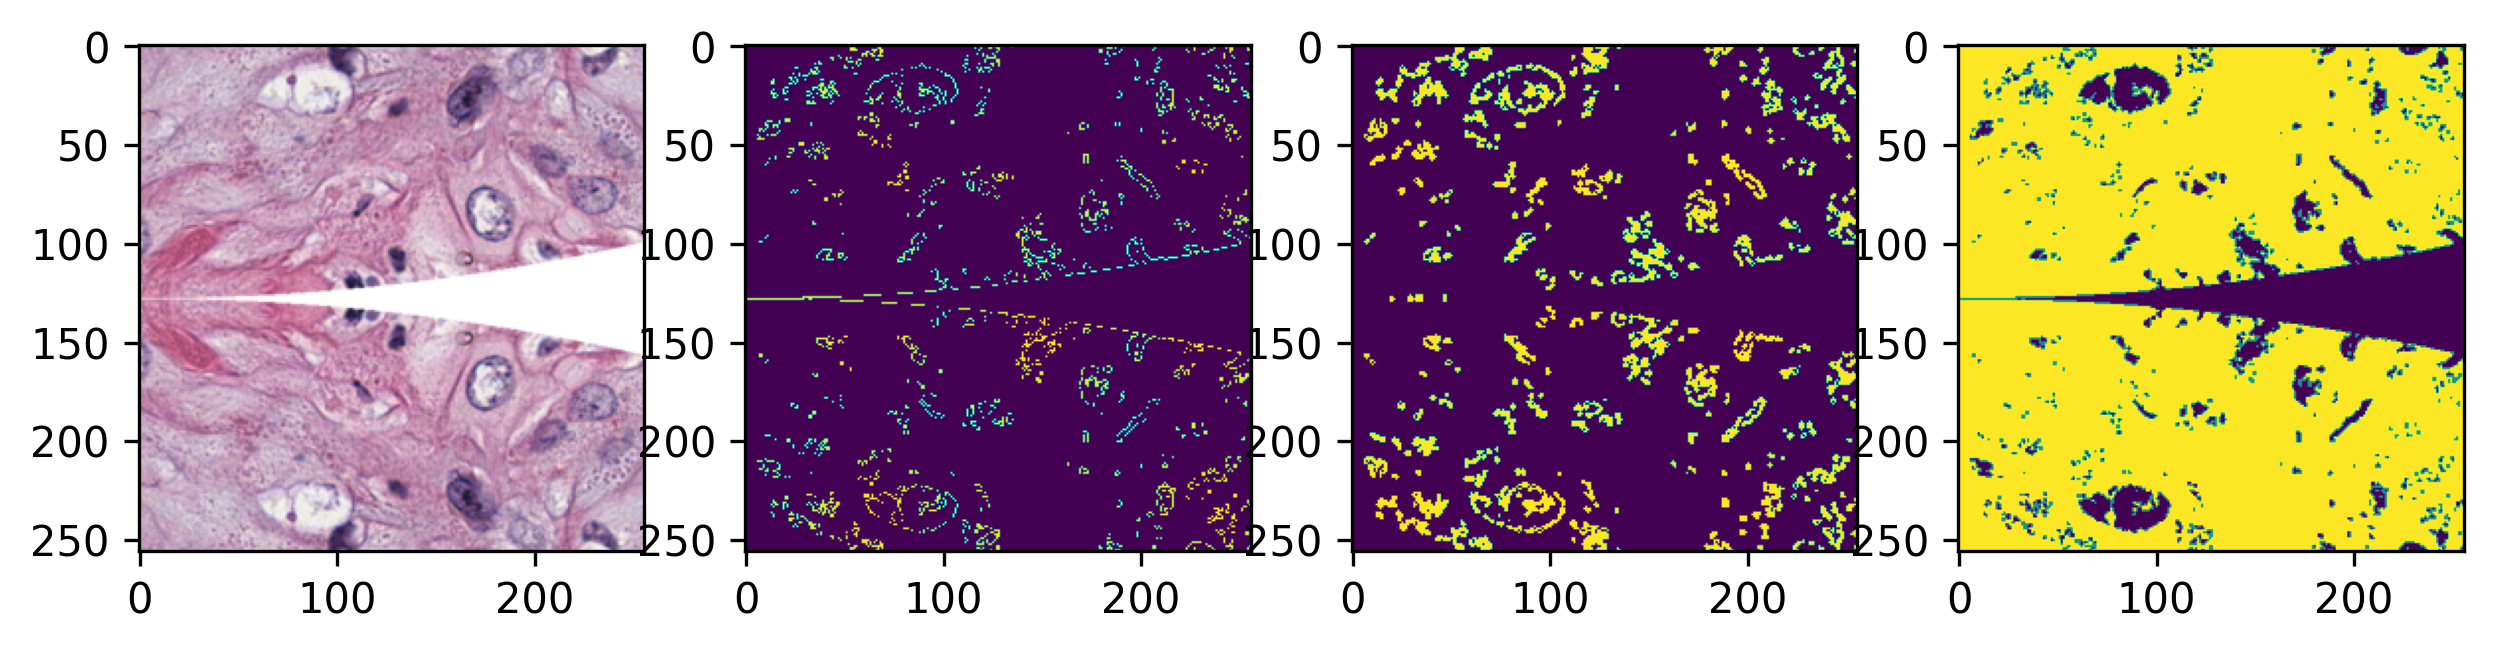

In [21]:
#visualize a single example to verify that it is correct
(img,patch_mask,patch_mask_weight)=dataset["test"][5]

print(img.shape, patch_mask.shape, patch_mask_weight.shape)
fig, ax = plt.subplots(1,4, figsize=(10,4))  # 1 row, 2 columns

#build output showing original patch  (after augmentation), class = 1 mask, weighting mask, overall mask (to see any ignored classes)
ax[0].imshow(np.moveaxis(img.numpy(),0,-1))
ax[1].imshow(patch_mask==1)
ax[2].imshow(patch_mask_weight)
ax[3].imshow(patch_mask)

In [22]:
#generate its output
#%%timeit
output=model(img[np.newaxis,...].to(device))
output=output.detach().squeeze().cpu().numpy()
output=np.moveaxis(output,0,-1) 

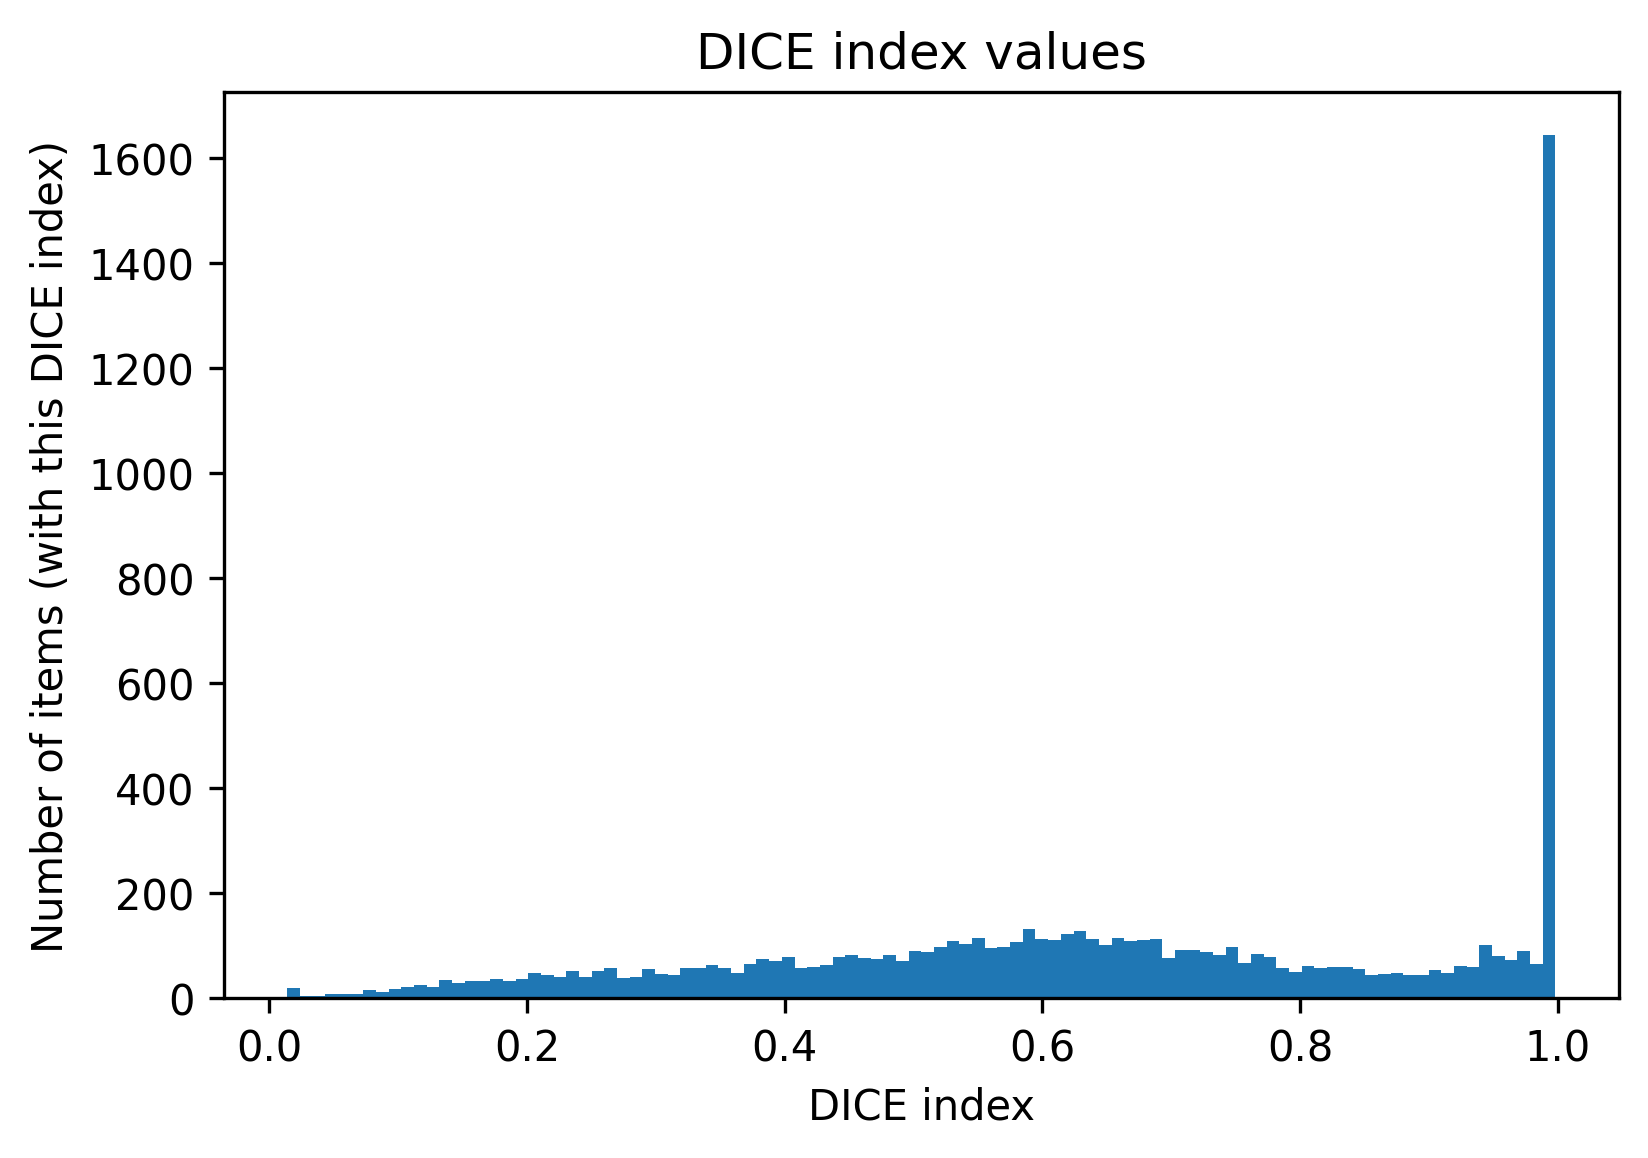

Mean DICE value: 0.6646343288421631


In [23]:
#Calculate dice indices
results = []
for i in range(len(dataset["test"])):
  #Get examples
  (img,patch_mask,patch_mask_weight)=dataset["test"][i]
  output=model(img[np.newaxis,...].to(device))
  output=output.detach().squeeze().cpu().numpy()
  output=np.moveaxis(output,0,-1)
  #Get prediction
  pred = np.argmax(output, axis = -1)
  #Calculate dice index
  matches = np.sum((pred == patch_mask))
  num_pixels = img.shape[1] * img.shape[2]
  dice_index = (2 * matches) / (2 * num_pixels)
  results.append(dice_index)

plt.hist(results, bins = 100)
plt.title("DICE index values")
plt.xlabel("DICE index")
plt.ylabel("Number of items (with this DICE index)")
plt.show()

print("Mean DICE value: " + str(np.mean(results)))

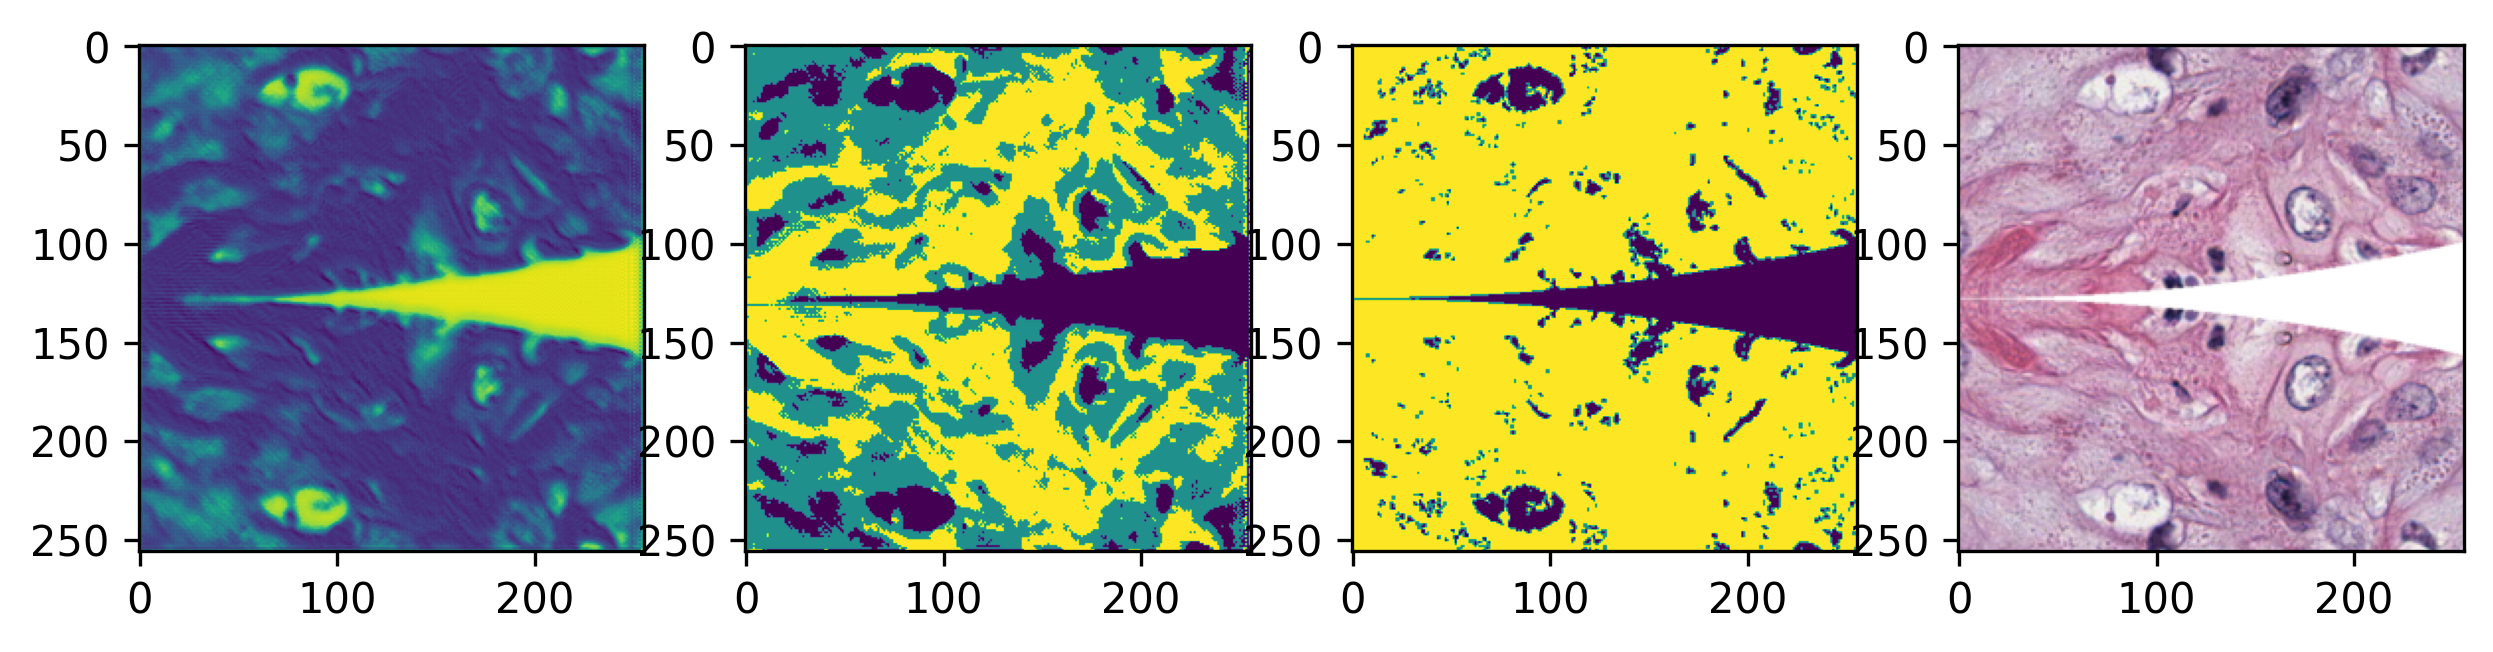

In [24]:
#visualize its result
(img,patch_mask,patch_mask_weight)=dataset["test"][5]
output=model(img[np.newaxis,...].to(device))
output=output.detach().squeeze().cpu().numpy()
output=np.moveaxis(output,0,-1)
fig, ax = plt.subplots(1,4, figsize=(10,4))  # 1 row, 2 columns

ax[0].imshow(output[...,0])
ax[1].imshow(np.argmax(output,axis=-1))
ax[2].imshow(patch_mask)
ax[3].imshow(np.moveaxis(img.numpy(),0,-1))

In [25]:
batch_size = 1 # nicer to have a single batch so that we can iterately 
               # view the output, while not consuming too much 
edge_weight = 1

In [26]:
# note that since we need the transofrmations to be reproducible for both masks and images
# we do the spatial transformations first, and afterwards do any color augmentations

# in the case of using this for output generation, we want to use the original 
# images since they will give a better sense of the exepected 
# output when used on the rest of the dataset, as a result, we disable all unnecessary augmentation.
# the only component that remains here is the randomcrop, to ensure that regardless of the size of the image
# in the database, we extract an appropriately sized patch
img_transform = transforms.Compose([
     transforms.ToPILImage(),
     transforms.Resize(patch_size),
    transforms.ToTensor()
    ])

mask_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(patch_size),
    ])

phases=["val"]
datasetB={}
dataLoader={}
for phase in phases:
    datasetB[phase]=Dataset( f"{dataname}_{phase}.pytable", # load from working directory
                           img_transform=img_transform, 
                           mask_transform = mask_transform,
                           edge_weight=edge_weight)
    dataLoader[phase]=DataLoader(datasetB[phase], batch_size=batch_size, 
                                shuffle=True, num_workers=0, pin_memory=True) #,pin_memory=True)

In [27]:
def infer_batch(model, batch_data, on_gpu):
        """Run inference on an input batch.
        This contains logic for forward operation as well as
        i/o aggregation.
        Args:
            model (nn.Module): PyTorch defined model.
            batch_data (ndarray): A batch of data generated by
              torch.utils.data.DataLoader.
            on_gpu (bool): Whether to run inference on a GPU.
        Returns:
            List of network output head, each output is a `ndarray`.
        """
        model.eval()

        imgs = batch_data
        imgs = imgs.to("cuda").type(torch.float32)

        with torch.inference_mode():
            logits = model(imgs)
            logits = logits.permute(0, 2, 3, 1) # as your output is channels first so swap them

        logits = logits.detach().squeeze().cpu().numpy()
        return [logits]

In [28]:
def preproc(image):
        """Define the pre-processing of this class of model."""
        # as before sending the patches we process them through the transforms
        # which will transform it and normalize it 
        return img_transform(image)

In [29]:
# adding the above function to our model as TIAToolbox will be looking for these
model.preproc_func = preproc
model.infer_batch = infer_batch

In [30]:
tissue_segmentor = SemanticSegmentor(model=model, num_loader_workers=4, batch_size=4)

# define the I/O configurations for tissue segmentation model
tissue_segmentor_ioconfig = IOSegmentorConfig(
    input_resolutions=[
            {'units': 'mpp', 'resolution': 2.0}
        ],
        output_resolutions=[
            {'units': 'mpp', 'resolution': 2.0}
        ],
        patch_input_shape=[patch_size, patch_size],
        patch_output_shape=[patch_size, patch_size],
        stride_shape=[patch_size, patch_size],
        save_resolution={'units': 'mpp', 'resolution': 8.0}
)

In [31]:
plt.imshow(plt.imread(files_test[0]))
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [33]:
tissue_mask_output = tissue_segmentor.predict(
        [files_test[0]],
        mode="tile",
        on_gpu=ON_GPU,
        ioconfig=tissue_segmentor_ioconfig,
        save_dir="drive/My Drive/CS424_CB/Courseworks/Coursework_3/results/a/b/c/d/e/f/g/h/i/j/k",
    )

Process Batch: 100%|############################| 81/81 [00:29<00:00,  2.79it/s]
|2022-03-30|09:51:05.871| [INFO] Finish: 0/1
|2022-03-30|09:51:05.875| [INFO] --Input: drive/My Drive/CS424_CB/Courseworks/Coursework_3/test_100/Copy of TCGA-CN-4725-01Z-00-DX1.fe518acf-cceb-4be4-b01a-63d66248d6d4_1.png
|2022-03-30|09:51:05.875| [INFO] --Ouput: /content/drive/My Drive/CS424_CB/Courseworks/Coursework_3/results/a/b/c/d/e/f/g/h/i/j/k/0


In [34]:
from matplotlib import cm
from tiatoolbox.utils.visualization import overlay_prediction_mask

wsi_prediction_raw = np.load(tissue_mask_output[0][1]+'.raw.0.npy') # Loading the first prediction [0] based on the output address [1]
print('Raw prediction dimensions: {}'.format(wsi_prediction_raw.shape))

Raw prediction dimensions: (1125, 1125, 3)


In [35]:
fig, ax = plt.subplots(1,2, figsize=(10,4))  # 1 row, 2 columns

ax[0].imshow(plt.imread(files_test[0]))
ax[1].imshow(np.argmax(wsi_prediction_raw,axis=-1))

Output hidden; open in https://colab.research.google.com to view.

#Task 2:

In [36]:
# install the openslide tools in the OS
!apt-get install openslide-tools

# install the lib for python
!pip install openslide-python

Reading package lists... Done
Building dependency tree       
Reading state information... Done
openslide-tools is already the newest version (3.4.1+dfsg-2).
0 upgraded, 0 newly installed, 0 to remove and 39 not upgraded.


In [37]:
# imports required for the tasks
import openslide as ops # for WSI handling
from skimage.filters.rank import entropy # for image manipulation
from skimage.morphology import disk
from skimage import measure
import numpy as np # for normal computation
import matplotlib.pyplot as plt # for visualization 

In [38]:
import glob
files2 = glob.glob("drive/My Drive/CS424_CB/Courseworks/Coursework_3/HPV-/*.svs")
for filen in files2:
  #read the wsi using function OpenSlide
  wsi_obj = ops.OpenSlide(filen)
  # printing the level using the same object
  print(f'There are {wsi_obj.level_count} level in the WSI')

  # printing the dimension of the levels
  for i,dims in enumerate(wsi_obj.level_dimensions):
    print(f'These are the dimensions {dims} for level {i}')
  print()
  thumbnail = wsi_obj.read_region((0,0), 2, wsi_obj.level_dimensions[2])
  plt.imshow(thumbnail)
  plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [39]:
files2b = glob.glob("drive/My Drive/CS424_CB/Courseworks/Coursework_3/HPV+/*.svs")
for filen in files2b:
  #read the wsi using function OpenSlide
  wsi_obj = ops.OpenSlide(filen)
  # printing the level using the same object
  print(f'There are {wsi_obj.level_count} level in the WSI')

  # printing the dimension of the levels
  for i,dims in enumerate(wsi_obj.level_dimensions):
    print(f'These are the dimensions {dims} for level {i}')
  print()
  thumbnail = wsi_obj.read_region((0,0), 2, wsi_obj.level_dimensions[2])
  plt.imshow(thumbnail)
  plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [40]:
#Store the regions of high cellularity
HPVmi = [[(7500, 1200), (7500, 15000), (10000, 15000), (110000, 10000), (6000, 7000)],
         [(9000, 4000), (9000, 12000), (17500, 24000), (67500, 6000), (67500, 10000)],
         [(17500, 10000), (14000, 14000), (64000, 8000), (67000, 10000), (70000, 17000)],
         [(15000, 10000), (14000, 14000), (67000, 10000), (70000, 17000), (19000, 14000)],
         [(12000, 10000), (10000, 14000), (40000, 13000), (50000, 19000), (90000, 10000)]]

HPVpi = [[(5000, 12000), (7000, 13000), (34000, 5000), (36000, 10000), (66000, 3000)],
         [(8000, 5000), (12000, 10000), (16000, 15000), (122000, 18000), (125000, 27000)],
         [(14000, 6000), (10000, 23000), (31000, 26000), (25000, 25000), (110000, 13000)],
         [(5000, 45000), (30000, 65000), (40000, 75000), (45000, 35000), (60000, 3000)],
         [(7000, 32000), (12000, 24000), (24000, 13000), (31000, 9000), (41000, 4000)]]

In [41]:
#Get 5 regions from each image with high cellularity
wsi_regions = []
files2m = glob.glob("drive/My Drive/CS424_CB/Courseworks/Coursework_3/HPV-/*.svs")
for i, filen in enumerate(files2m):
  #read the wsi using function OpenSlide
  wsi_obj = ops.OpenSlide(filen)
  for j in range(5):
    # printing the dimension of the levels
    thumbnail = wsi_obj.read_region(HPVmi[i][j], 2, (512, 512))
    wsi_regions.append(np.array(thumbnail))
    plt.imshow(thumbnail)
    plt.show()

files2p = glob.glob("drive/My Drive/CS424_CB/Courseworks/Coursework_3/HPV+/*.svs")
for i, filen in enumerate(files2p):
  #read the wsi using function OpenSlide
  wsi_obj = ops.OpenSlide(filen)
  for j in range(5):
    # printing the dimension of the levels
    thumbnail = wsi_obj.read_region(HPVpi[i][j], 2, (512, 512))
    wsi_regions.append(np.array(thumbnail))
    plt.imshow(thumbnail)
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [42]:
#Change the data so that we can make predictions
wsi_regions = np.array(wsi_regions)[...,:3]

wsi_regions = np.moveaxis(wsi_regions, 3, 1)

wsi_regions_tensor = []
for i in range(wsi_regions.shape[0]):
  img = wsi_regions[i,:]
  wsi_regions_tensor.append(img_transform(np.moveaxis(img,0,-1)))

wsi_regions_tensor = torch.stack(wsi_regions_tensor)

(50, 512, 512, 3)
(50, 3, 512, 512)
torch.Size([50, 3, 256, 256])


In [43]:
#Use task 1 to make the predictions
pred = model(wsi_regions_tensor.to(device))
pred = pred.detach().squeeze().cpu().numpy()
pred = np.moveaxis(pred,1,-1)
pred = np.argmax(pred, axis = -1)

In [69]:
#Use task 1 to make the prediction images
for i in range(50):
  plt.figure(figsize = (7,2))
  plt.subplot(1,2,1)
  plt.imshow(np.moveaxis(wsi_regions[i, :], 0, -1))
  plt.title("Original image")
  plt.show()

  plt.figure(figsize = (7,2))
  plt.subplot(1,2,2)
  plt.imshow(pred[i,:])
  plt.title("Prediction image")
  plt.show()

Output hidden; open in https://colab.research.google.com to view.